# 🛠️ Our Features — Building Age Classification
## ZAS Data Science Hackathon · Team notebook 01 (replaces starter Notebook 3)

**Goal:** turn each pixel's cleaned 42-year history into a **feature vector** (one row per pixel) that
1. separates the 4 age classes well in **Madrid**, and
2. **transfers** to **Amsterdam** with few labels — the 25-samples-per-class prize.

**Input:** the clean files made by `00-Our_Data_Explained.ipynb` (folder `clean/`).
**Output:** `features/` — feature tables for both cities, the list of feature groups, and the **ablation table**.

| Part | What happens |
|---|---|
| 0 | Jargon used in this notebook |
| 1 | Setup and loading |
| 2 | From long table to a **data cube** (pixels × years × channels) |
| 3 | Spectral indices (old 5 + new ones) |
| 4 | Feature groups A–H, each explained and visualised |
| 5 | The evaluation protocol used for every experiment |
| 6 | **The ablation table** — adding one group at a time |
| 7 | Leave-one-group-out — which groups really matter |
| 8 | Label-side experiments (coverage weights, the 1960 pile) |
| 9 | Few-shot curve for the final feature set (F1 vs log₂ n) |
| 10 | Saving features for the modelling notebook |
| 11 | Summary & decisions |

---
# Part 0 — Jargon

| Term | Meaning |
|---|---|
| **Feature** | One number describing a pixel (e.g. "median NDVI over 42 years"). |
| **Feature vector / feature table** | All features of a pixel in one row; one row per pixel. |
| **Feature group** | A family of related features we switch on/off together (e.g. "change-point features"). |
| **Data cube** | A 3-D array: pixels × years × channels. Easy to compute statistics along the year axis. |
| **Channel** | A band (Blue … SWIR2) or an index (NDVI …) stored in the cube. |
| **Real vs filled years** | *Real* = the year had a clean observation. *Filled* = we interpolated it. |
| **Interpolation** | Estimating a missing year from the years around it (straight line between neighbours). |
| **Median / percentile / IQR** | Robust statistics: not pulled around by one odd year. IQR = 75th − 25th percentile. |
| **Slope (trend)** | How fast a value rises or falls per year (fitted straight line). |
| **Change-point / step fit** | Find the year where the series jumps from one level to another — usually construction. |
| **Break strength** | Share of the pixel's variation explained by that single jump (0 = no jump, 1 = perfect step). |
| **Relative feature** | Compares the pixel with itself (late − early, ratios), so the city's overall brightness cancels. |
| **Spatial / neighbourhood feature** | Average of a feature over the surrounding pixels (3×3, 7×7, 15×15 windows). |
| **Leave-self-out** | A neighbourhood average that excludes the pixel itself. |
| **Per-city standardisation** | Shift and scale each feature to mean 0, std 1 *within each city*, using no labels. |
| **Ablation** | Adding (or removing) one ingredient at a time and measuring the effect. |
| **Spatial-block CV** | Cross-validation where whole 2 km × 2 km blocks are held out — no near-identical neighbours leak into training. |
| **Zero-shot** | Apply the Madrid model to Amsterdam with no Amsterdam labels. |
| **Few-shot (n per class)** | Adapt to Amsterdam using only n labelled pixels per class (support set); test on the rest (query set). |
| **Prototype classifier** | Average the support pixels of each class (prototype); give each query pixel the class of the nearest prototype. |
| **Recalibration** | Keep the Madrid model, but learn from the support set how to re-map its class probabilities for Amsterdam. |
| **HistGradientBoosting (HGB)** | Fast gradient-boosted decision trees in scikit-learn; handles missing values natively. |

---
# Part 1 — Setup and loading

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, time, warnings
import matplotlib.patches as mpatches
from pathlib import Path
from scipy.ndimage import uniform_filter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, confusion_matrix
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

DATA_DIR = next(Path(p) for p in ['data', '../data', '.'] if (Path(p) / 'madrid_train.parquet').exists())   # repo: put the parquet files in data/
CLEAN_DIR = DATA_DIR / 'clean'
FEAT_DIR  = DATA_DIR / 'features'; FEAT_DIR.mkdir(exist_ok=True)

CITIES  = ['Madrid', 'Amsterdam']
BANDS   = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
PID     = ['px_key', 'py_key']
YEARS   = np.arange(1984, 2026)
EARLY   = YEARS <= 2003
LATE    = YEARS >= 2004
CLASSES = np.array([1, 2, 3, 4])
CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CITY_COLORS  = {'Madrid': '#c0392b', 'Amsterdam': '#2c6fbb'}
SEED = 42

yearly = {c: pd.read_parquet(CLEAN_DIR / f'{c.lower()}_yearly_clean.parquet') for c in CITIES}
pixels = {c: pd.read_parquet(CLEAN_DIR / f'{c.lower()}_pixels.parquet').sort_values(PID).reset_index(drop=True) for c in CITIES}
for c in CITIES:
    print(f"{c:10s}: {len(yearly[c]):,} clean pixel-years | {len(pixels[c]):,} pixels")

Madrid    : 3,147,969 clean pixel-years | 76,263 pixels
Amsterdam : 1,058,169 clean pixel-years | 25,992 pixels


---
# Part 2 — From a long table to a data cube

The clean table has one row per (pixel, year). To compute statistics along time quickly we **reshape it into a cube**: for every channel, a matrix of **pixels × 42 years**.

We keep two versions of every channel:
- **`real`** — the observed value, `NaN` where the year had no clean photo. Used for statistics (honest: no invented values).
- **`filled`** — gaps filled by straight-line interpolation (ends: nearest real year). Used only where a complete series is required (year-to-year jumps, step fitting).

We also keep a **mask** (`True` = real year) so the model can know how much of a series was invented.

In [2]:
def make_cube(yr, pix):
    wide = (yr.set_index(PID + ['year'])[BANDS].unstack('year')
              .reindex(pd.MultiIndex.from_frame(pix[PID])))
    cube = {}
    for b in BANDS:
        cube[b] = wide[b].reindex(columns=YEARS).to_numpy(np.float32)
    mask = ~np.isnan(cube['Blue'])
    return cube, mask

def fill_gaps(M):
    # interpolate along years (axis 1); ends take the nearest real value
    return pd.DataFrame(M.T).interpolate(limit_direction='both').to_numpy(np.float32).T

cube, mask = {}, {}
for c in CITIES:
    t = time.time()
    cube[c], mask[c] = make_cube(yearly[c], pixels[c])
    print(f"{c:10s}: cube {len(pixels[c]):,} pixels × {len(YEARS)} years | real years: {mask[c].mean():.1%}  ({time.time()-t:.1f}s)")

Madrid    : cube 76,263 pixels × 42 years | real years: 98.3%  (0.6s)
Amsterdam : cube 25,992 pixels × 42 years | real years: 96.9%  (0.2s)


---
# Part 3 — Spectral indices

Indices are **ratios between bands**. A ratio cancels overall brightness (sun angle, haze, sensor, city), which makes them the most *transferable* signals.

| Index | Formula | Captures | New? |
|---|---|---|---|
| NDVI | (NIR − Red)/(NIR + Red) | vegetation | starter |
| NDBI | (SWIR1 − NIR)/(SWIR1 + NIR) | built-up surface | starter |
| UI | (SWIR2 − NIR)/(SWIR2 + NIR) | urban surface | starter |
| MNDWI | (Green − SWIR1)/(Green + SWIR1) | water / wetness | starter |
| BSI | ((SWIR1+Red) − (NIR+Blue)) / sum | bare soil, construction sites | starter |
| **NBR** | (NIR − SWIR2)/(NIR + SWIR2) | vegetation vs bare/burnt surfaces | ✅ new |
| **NDTI** | (SWIR1 − SWIR2)/(SWIR1 + SWIR2) | roofing / mineral materials | ✅ new |
| **TCB, TCG, TCW** | Tasselled-cap brightness, greenness, wetness (fixed weighted sums of the 6 bands, OLI coefficients, Baig et al. 2014) | overall brightness, vegetation, moisture | ✅ new |

Tasselled cap needs true reflectance, so we convert: **reflectance = value × 0.0000275 − 0.2** (Landsat Collection-2 scale).

In [3]:
IDX_STARTER = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI']
IDX_NEW     = ['NBR', 'NDTI', 'TCB', 'TCG', 'TCW']
TC = {'TCB': [0.3029, 0.2786, 0.4733, 0.5599, 0.5080, 0.1872],
      'TCG': [-0.2941, -0.2430, -0.5424, 0.7276, 0.0713, -0.1608],
      'TCW': [0.1511, 0.1973, 0.3283, 0.3407, -0.7117, -0.4559]}

def add_indices(cb):
    B, G, R, N, S1, S2 = (cb[b] for b in BANDS); e = 1e-6
    cb['NDVI']  = (N - R) / (N + R + e)
    cb['NDBI']  = (S1 - N) / (S1 + N + e)
    cb['UI']    = (S2 - N) / (S2 + N + e)
    cb['MNDWI'] = (G - S1) / (G + S1 + e)
    cb['BSI']   = ((S1 + R) - (N + B)) / ((S1 + R) + (N + B) + e)
    cb['NBR']   = (N - S2) / (N + S2 + e)
    cb['NDTI']  = (S1 - S2) / (S1 + S2 + e)
    refl = [cb[b] * 2.75e-5 - 0.2 for b in BANDS]
    for k, w in TC.items():
        cb[k] = sum(wi * r for wi, r in zip(w, refl)).astype(np.float32)
    return cb

CHANNELS = BANDS + IDX_STARTER + IDX_NEW
real, filled = {}, {}
for c in CITIES:
    real[c] = add_indices(dict(cube[c]))
    filled[c] = {ch: fill_gaps(real[c][ch]) for ch in CHANNELS}
    print(f"{c:10s}: {len(CHANNELS)} channels ready")

pd.DataFrame({c: {ch: np.nanmedian(real[c][ch]) for ch in IDX_STARTER + IDX_NEW} for c in CITIES}).round(3).T

Madrid    : 16 channels ready


Amsterdam : 16 channels ready


,NDVI,NDBI,UI,MNDWI,BSI,NBR,NDTI,TCB,TCG,TCW
Madrid,0.087,0.024,-0.021,-0.163,0.053,0.021,0.043,0.427,0.005,-0.103
Amsterdam,0.139,-0.017,-0.069,-0.141,0.009,0.069,0.052,0.275,0.039,-0.059


Amsterdam is greener (NDVI, TCG) and darker (TCB) than Madrid — the domain shift we saw in notebook 00. Most features below are built so that this difference matters less.

---
# Part 4 — Feature groups

Every group is a function that takes **only the cube** (no labels!) and returns a table with one row per pixel. Pixels in both cities go through exactly the same code.

| Group | Name | Idea |
|---|---|---|
| **S** | Starter-like | the starter notebook's 58 features (minus its 2 constant flags) |
| **A** | New indices | NBR, NDTI, tasselled cap: mean, std, early, late |
| **B** | Robust stats & trends | median, IQR, 10th/90th percentile, slopes, volatility |
| **C** | Time windows | median of 6-year windows → *when* things changed |
| **D** | Change-point | year, size and strength of the main jump; biggest single-year jump |
| **E** | Relative | late − early, late ÷ early, band "shape" |
| **F** | Quality | coverage, % filled years, longest gap, photos per year |
| **G** | Spatial context | neighbourhood averages at 90 m, 210 m, 450 m; building density |

### Helper statistics

In [4]:
def nmean(M, ax=1):  return np.nanmean(M, ax)
def nstd(M, ax=1):   return np.nanstd(M, ax, ddof=1)
def nmed(M, ax=1):   return np.nanmedian(M, ax)
def npct(M, q):      return np.nanpercentile(M, q, axis=1)

def masked_slope(R, yrs):
    # least-squares slope per row, using only real (non-NaN) years
    x = np.where(np.isnan(R), np.nan, yrs[None, :].astype(np.float32))
    xm, ym = np.nanmean(x, 1, keepdims=True), np.nanmean(R, 1, keepdims=True)
    num = np.nansum((x - xm) * (R - ym), 1); den = np.nansum((x - xm) ** 2, 1)
    return np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)

def longest_gap(m):
    run = np.zeros(len(m)); best = np.zeros(len(m))
    for t in range(m.shape[1]):
        run = (run + 1) * (~m[:, t]); best = np.maximum(best, run)
    return best

### Group S — starter-like features (our baseline)

Same recipe as starter Notebook 3: mean & std of bands and the 5 starter indices, early (≤2003) and late (≥2004) mean & std of bands, and the mean & std of year-on-year changes. We drop `has_early_data` / `has_late_data` (constant — notebook 00).

In [5]:
def feats_S(R, F):
    out = {}
    for ch in BANDS + IDX_STARTER:
        out[f'{ch}_mean'] = nmean(R[ch]); out[f'{ch}_std'] = nstd(R[ch])
    for b in BANDS:
        out[f'{b}_early_mean'] = nmean(R[b][:, EARLY]); out[f'{b}_early_std'] = nstd(R[b][:, EARLY])
        out[f'{b}_late_mean']  = nmean(R[b][:, LATE]);  out[f'{b}_late_std']  = nstd(R[b][:, LATE])
        d = np.diff(F[b], axis=1)
        out[f'd_{b}_mean'] = d.mean(1); out[f'd_{b}_std'] = d.std(1, ddof=1)
    return pd.DataFrame(out)

### Group A — new indices

In [6]:
def feats_A(R, F):
    out = {}
    for ch in IDX_NEW:
        out[f'{ch}_mean'] = nmean(R[ch]); out[f'{ch}_std'] = nstd(R[ch])
        out[f'{ch}_early_mean'] = nmean(R[ch][:, EARLY]); out[f'{ch}_late_mean'] = nmean(R[ch][:, LATE])
    return pd.DataFrame(out)

### Group B — robust statistics, trends, volatility

For the key channels `K` we compute:
- **median, IQR, p10, p90** — robust level and spread;
- **slope** over all years, **early slope** (1984–2003), **late slope** (2004+) — direction of change;
- **volatility** = median absolute change between consecutive *real* years — how jumpy the pixel is.

In [7]:
K = ['NDVI', 'NDBI', 'MNDWI', 'BSI', 'NBR', 'NDTI', 'TCB', 'TCG', 'TCW', 'SWIR1', 'NIR']

def feats_B(R, F):
    out = {}
    for ch in K:
        M = R[ch]
        p10, p25, p50, p75, p90 = (npct(M, q) for q in (10, 25, 50, 75, 90))
        out[f'{ch}_med'] = p50; out[f'{ch}_iqr'] = p75 - p25; out[f'{ch}_p10'] = p10; out[f'{ch}_p90'] = p90
        out[f'{ch}_slope']       = masked_slope(M, YEARS)
        out[f'{ch}_slope_early'] = masked_slope(M[:, EARLY], YEARS[EARLY])
        out[f'{ch}_slope_late']  = masked_slope(M[:, LATE], YEARS[LATE])
        out[f'{ch}_volatility']  = nmed(np.abs(np.diff(M, axis=1)))
    return pd.DataFrame(out)

### Group C — time windows

Seven 6-year windows (1984–89, 1990–95, …, 2020–25). The median of each window for a few channels tells the model **when** the pixel changed, not only whether it changed.

In [8]:
WINDOWS = [(1984, 1989), (1990, 1995), (1996, 2001), (2002, 2007), (2008, 2013), (2014, 2019), (2020, 2025)]
WCH = ['NDVI', 'NDBI', 'BSI', 'TCB', 'SWIR1']

def feats_C(R, F):
    out = {}
    for ch in WCH:
        for a, b in WINDOWS:
            sel = (YEARS >= a) & (YEARS <= b)
            out[f'{ch}_w{a}'] = nmed(R[ch][:, sel])
    return pd.DataFrame(out)

### Group D — change-point (construction) features ⭐

**Idea:** a building constructed while the satellite was watching shows a **step** in its series: one level before construction, another after.

For every pixel and every possible split year we compute how much of the series a two-level step explains; the best split gives:
- **`brk_year`** — first year of the new level (≈ construction),
- **`brk_size`** — after-level − before-level,
- **`brk_strength`** — share of variation explained (0 – 1).

Done for 7 channels at once with cumulative sums (fast, no loops over pixels). We also add the **year and size of the single biggest year-to-year jump**, and a combined `brk_year_best` from the channel with the strongest step.

Expected: **Class 4** → strong break after 2004 · **Class 3** → break 1984–2004 · **Classes 1–2** → weak breaks.

In [9]:
DCH = ['NDVI', 'NDBI', 'BSI', 'SWIR1', 'TCB', 'TCW', 'NBR']

def step_break(Y, yrs):
    T = Y.shape[1]; k = np.arange(1, T)
    cs = np.cumsum(Y, axis=1, dtype=np.float64)[:, :-1]
    tot = Y.sum(1, keepdims=True, dtype=np.float64)
    before, after = cs / k, (tot - cs) / (T - k)
    gain = k * (T - k) / T * (after - before) ** 2
    best = gain.argmax(1); i = np.arange(len(Y))
    strength = gain[i, best] / (Y.var(1, dtype=np.float64) * T + 1e-12)
    return yrs[best + 1], (after - before)[i, best], strength

def feats_D(R, F):
    out = {}
    strengths, years_ = [], []
    for ch in DCH:
        y, s, st = step_break(F[ch], YEARS)
        out[f'{ch}_brk_year'] = y; out[f'{ch}_brk_size'] = s; out[f'{ch}_brk_strength'] = st
        out[f'{ch}_brk_after2004'] = (y >= 2004) * st          # strength of a post-2004 break
        strengths.append(st); years_.append(y)
    S, Yr = np.vstack(strengths), np.vstack(years_)
    out['brk_year_best'] = Yr[S.argmax(0), np.arange(S.shape[1])]
    out['brk_strength_max'] = S.max(0)
    for ch in ['NDVI', 'NDBI', 'SWIR1']:
        d = np.diff(F[ch], axis=1); j = np.abs(d).argmax(1)
        out[f'{ch}_jump_year'] = YEARS[j + 1]; out[f'{ch}_jump_size'] = d[np.arange(len(d)), j]
    return pd.DataFrame(out)

### Group E — relative features (compare the pixel with itself)

- **late − early** median for the key channels: what changed between the two 20-year halves.
- **late ÷ early** for the 6 bands.
- **band shape**: each band's median divided by the sum of all 6 — the *colour shape* independent of brightness.

These cancel most of Amsterdam's "darker overall" effect.

In [10]:
def feats_E(R, F):
    out = {}
    for ch in K:
        out[f'{ch}_late_minus_early'] = nmed(R[ch][:, LATE]) - nmed(R[ch][:, EARLY])
    meds = {b: nmed(R[b]) for b in BANDS}; tot = sum(meds.values())
    for b in BANDS:
        out[f'{b}_late_over_early'] = nmed(R[b][:, LATE]) / nmed(R[b][:, EARLY])
        out[f'{b}_shape'] = meds[b] / tot
    return pd.DataFrame(out)

### Group F — quality and coverage

- `coverage` — how much of the pixel is building (higher → cleaner signal and label).
- `frac_filled` — share of years that had no clean photo (interpolated).
- `longest_gap` — longest run of missing years.
- `photos_per_year` — average photos behind each yearly value; `frac_fallback` — share of years where no warm-season photo existed.

In [11]:
def feats_F(c):
    yr = yearly[c].groupby(PID).agg(photos_per_year=('n_photos', 'mean'),
                                    frac_fallback=('season', lambda s: (s == 'fallback').mean()))
    yr = yr.reindex(pd.MultiIndex.from_frame(pixels[c][PID])).reset_index(drop=True)
    return pd.DataFrame({'coverage': pixels[c].coverage.values,
                         'frac_filled': 1 - mask[c].mean(1),
                         'longest_gap': longest_gap(mask[c]),
                         'photos_per_year': yr.photos_per_year.values,
                         'frac_fallback': yr.frac_fallback.values})

### Build groups S, A–F for both cities

In [12]:
groups = {}
for c in CITIES:
    t = time.time(); R, F = real[c], filled[c]
    groups[c] = {'S': feats_S(R, F), 'A': feats_A(R, F), 'B': feats_B(R, F), 'C': feats_C(R, F),
                 'D': feats_D(R, F), 'E': feats_E(R, F), 'F': feats_F(c)}
    print(f"{c:10s}: " + ', '.join(f"{g}={d.shape[1]}" for g, d in groups[c].items()) + f"   ({time.time()-t:.0f}s)")

Madrid    : S=58, A=20, B=88, C=35, D=36, E=23, F=5   (188s)


Amsterdam : S=58, A=20, B=88, C=35, D=36, E=23, F=5   (68s)


### Group G — spatial context (neighbourhood features)

Notebook 00 showed a neighbouring pixel has the **same class 76 % (Madrid) / 87 % (Amsterdam)** of the time. So the *surroundings* are a strong clue.

For a set of key features we compute the **leave-self-out average over 3×3, 7×7 and 15×15 windows** (≈ 90 m, 210 m, 450 m), plus:
- **building density** — share of window cells that are building pixels (dense old centres vs sparse suburbs);
- **local spread** — std of NDVI median and break year in the 7×7 window (uniform estate vs mixed area);
- **pixel − neighbourhood** — how much the pixel stands out.

⚠️ Only neighbours' **features** are used — never their labels.

In [13]:
def grid_xy(pix):
    return (pix.px_key - pix.px_key.min()).to_numpy(), (pix.py_key - pix.py_key.min()).to_numpy()

def neigh(pix, v, size, stat='mean'):
    x, y = grid_xy(pix); H, W = y.max() + 1, x.max() + 1
    ok = ~np.isnan(v)
    V = np.zeros((H, W)); M = np.zeros((H, W)); V2 = np.zeros((H, W))
    V[y[ok], x[ok]] = v[ok]; M[y[ok], x[ok]] = 1; V2[y[ok], x[ok]] = v[ok] ** 2
    n = size ** 2
    s  = uniform_filter(V, size, mode='constant') * n - V
    s2 = uniform_filter(V2, size, mode='constant') * n - V2
    m  = uniform_filter(M, size, mode='constant') * n - M
    m_ = m[y, x]
    mean = np.where(m_ > 0, s[y, x] / np.maximum(m_, 1), np.nan)
    if stat == 'mean': return mean
    var = np.where(m_ > 1, s2[y, x] / np.maximum(m_, 1) - mean ** 2, np.nan)
    return np.sqrt(np.clip(var, 0, None))

def density(pix, size):
    x, y = grid_xy(pix); M = np.zeros((y.max() + 1, x.max() + 1)); M[y, x] = 1
    return (uniform_filter(M, size, mode='constant') * size ** 2 - 1)[y, x] / (size ** 2 - 1)

GKEYS = ['NDVI_med', 'NDBI_med', 'TCB_med', 'SWIR1_med', 'NDVI_late_minus_early',
         'NDVI_brk_strength', 'NDVI_brk_year', 'NDBI_brk_size', 'coverage']

def feats_G(c):
    pix = pixels[c]; base = pd.concat(groups[c].values(), axis=1); out = {}
    for f in GKEYS:
        v = base[f].to_numpy(np.float64)
        for s in (3, 7, 15):
            out[f'nb{s}_{f}'] = neigh(pix, v, s)
    for s in (3, 7, 15):
        out[f'density{s}'] = density(pix, s)
    for f in ['NDVI_med', 'NDVI_brk_year']:
        out[f'nbstd7_{f}'] = neigh(pix, base[f].to_numpy(np.float64), 7, 'std')
    for f in ['NDVI_med', 'TCB_med']:
        out[f'diff7_{f}'] = base[f].to_numpy() - out[f'nb7_{f}']
    return pd.DataFrame(out)

for c in CITIES:
    groups[c]['G'] = feats_G(c)
    print(f"{c:10s}: G={groups[c]['G'].shape[1]} spatial features")

GROUP_COLS = {g: list(groups['Madrid'][g].columns) for g in groups['Madrid']}
FEATS = {c: pd.concat(groups[c].values(), axis=1) for c in CITIES}
y = {c: pixels[c].age_class.to_numpy() for c in CITIES}
print("Total features:", sum(len(v) for v in GROUP_COLS.values()), {g: len(v) for g, v in GROUP_COLS.items()})
assert all(list(FEATS['Madrid'].columns) == list(FEATS['Amsterdam'].columns) for _ in [0])
assert not any(col in FEATS['Madrid'].columns for col in ['age_class', 'wmy', 'weighted_mean_year']), "label leaked into features!"

Madrid    : G=34 spatial features


Amsterdam : G=34 spatial features
Total features: 299 {'S': 58, 'A': 20, 'B': 88, 'C': 35, 'D': 36, 'E': 23, 'F': 5, 'G': 34}


### Do the new features carry age signal? A first look

Before any model: the **change-point features by class** (Madrid and Amsterdam).

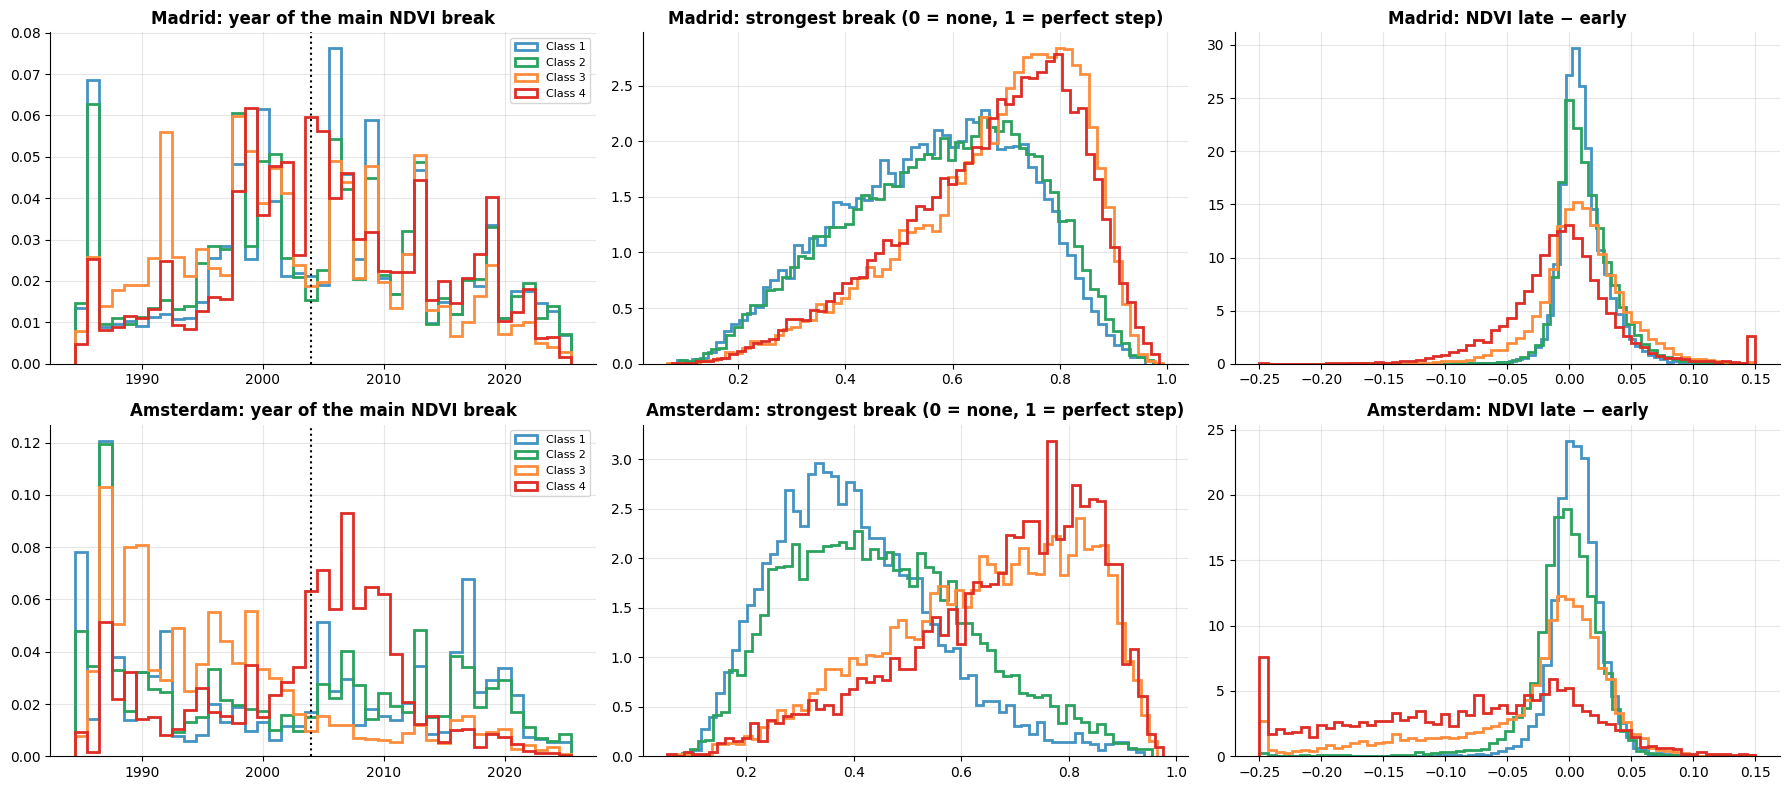

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for r, c in enumerate(CITIES):
    F_ = FEATS[c]
    for k in CLASSES:
        sel = y[c] == k
        axes[r, 0].hist(F_.loc[sel, 'NDVI_brk_year'], bins=np.arange(1984.5, 2026, 1), histtype='step', lw=2,
                        density=True, color=CLASS_COLORS[k], label=f'Class {k}')
        axes[r, 1].hist(F_.loc[sel, 'brk_strength_max'], bins=60, histtype='step', lw=2, density=True, color=CLASS_COLORS[k])
        axes[r, 2].hist(F_.loc[sel, 'NDVI_late_minus_early'].clip(-.25, .15), bins=60, histtype='step', lw=2,
                        density=True, color=CLASS_COLORS[k])
    axes[r, 0].set_title(f'{c}: year of the main NDVI break', fontweight='bold'); axes[r, 0].legend(fontsize=8)
    axes[r, 1].set_title(f'{c}: strongest break (0 = none, 1 = perfect step)', fontweight='bold')
    axes[r, 2].set_title(f'{c}: NDVI late − early', fontweight='bold')
    for x in (2004,): axes[r, 0].axvline(x, color='k', ls=':')
plt.tight_layout(); plt.show()

**How to read it:** if the change-point idea works, the class-4 curve (red) should pile up **after 2004** in the left panels and sit further right (stronger breaks) in the middle panels, class 3 (orange) should peak between 1984 and 2004, and classes 1–2 should be flatter. The right panels show that pixels which lost vegetation (negative late − early) lean towards the newer classes.

**What the plots actually show:**
- **Break strength (middle) is the clearest signal**: classes 3 & 4 (built while the satellite watched) have strong breaks (peak ≈ 0.8); classes 1 & 2 weak ones (≈ 0.4–0.6). In **Amsterdam** the separation is even sharper — this feature transfers.
- **Break year (left)**: in Amsterdam, class 4 clearly concentrates **after 2004** and class 3 before it. In Madrid the picture is noisier; the spikes at 1985–86 are edge effects (a step can always be fitted near the start of a series).
- **NDVI late − early (right)**: classes 3 and especially 4 have long negative tails — vegetation replaced by buildings.

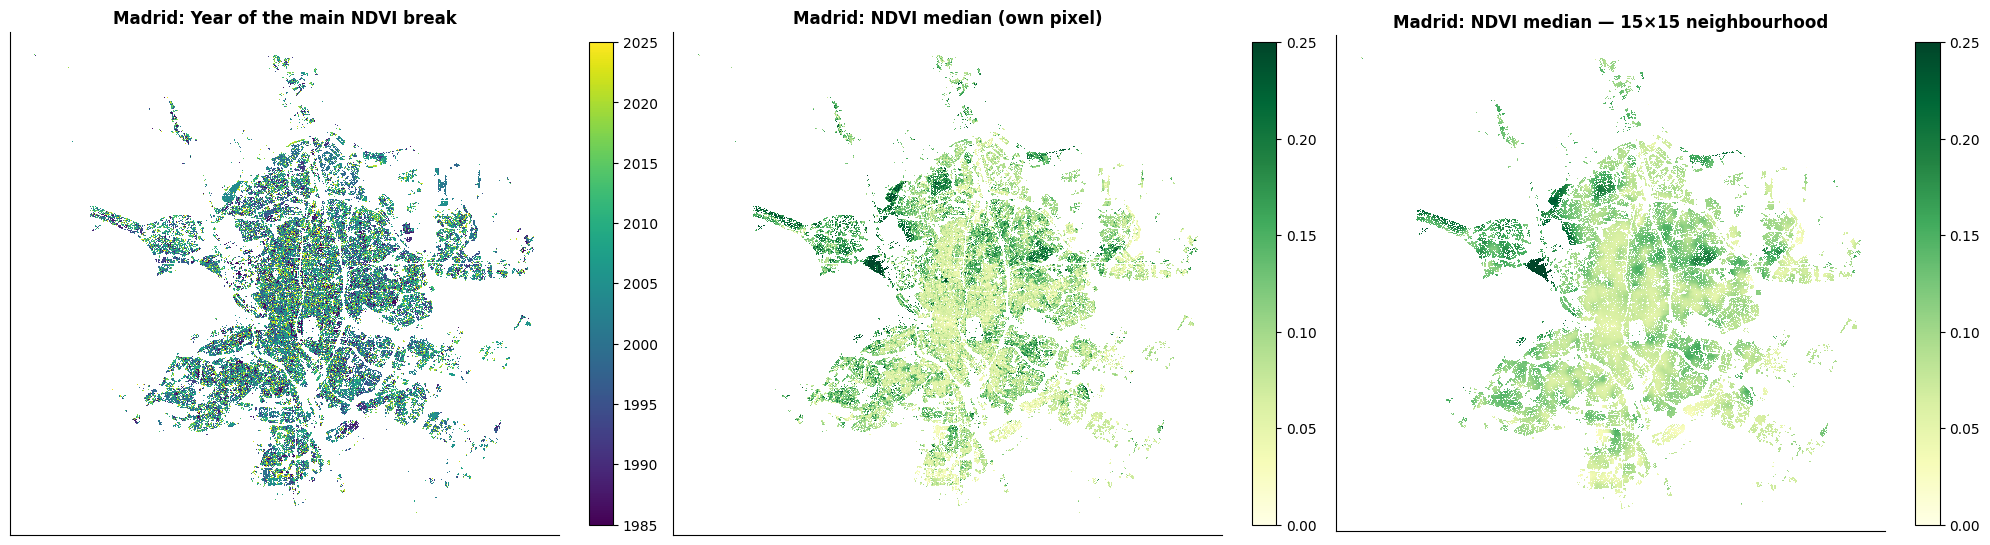

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
c = 'Madrid'; p = pixels[c]; F_ = FEATS[c]
items = [('NDVI_brk_year', 'Year of the main NDVI break', 'viridis', (1985, 2025)),
         ('NDVI_med', 'NDVI median (own pixel)', 'YlGn', (0, .25)),
         ('nb15_NDVI_med', 'NDVI median — 15×15 neighbourhood', 'YlGn', (0, .25))]
for ax, (f, title, cmap, (lo, hi)) in zip(axes, items):
    sc = ax.scatter(p.px_key, p.py_key, c=F_[f], s=.5, marker='s', cmap=cmap, vmin=lo, vmax=hi, linewidths=0)
    ax.set_aspect('equal'); ax.set_title(f'{c}: {title}', fontweight='bold'); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(sc, ax=ax, fraction=.04)
plt.tight_layout(); plt.show()

**Left:** break years form coherent patches — whole developments were built at the same time. Compare with the class map in notebook 00. **Middle vs right:** the neighbourhood average is a smoothed version of the pixel's own value; it removes pixel-level noise and describes the *district*.

---
# Part 5 — Evaluation protocol (identical for every experiment)

To compare feature sets fairly, **everything except the features stays fixed**:

| Metric | How | Why |
|---|---|---|
| **Madrid spatial CV** | 5-fold `StratifiedGroupKFold`, groups = 2 km × 2 km blocks | honest home-city performance |
| **Amsterdam zero-shot** | train on all Madrid, predict all Amsterdam | raw transferability |
| **Amsterdam n=25 · prototype** | 25 labelled pixels per class → class means in (per-city standardised) feature space → nearest mean; test on the rest; 10 random draws | starter-notebook transfer method |
| **Amsterdam n=25 · recalibrated** | 25 per class → logistic regression that re-maps the Madrid model's 4 log-probabilities; test on the rest; 10 draws | transfer that **uses** the Madrid model |

Model: `HistGradientBoostingClassifier` (300 trees, learning rate 0.08, `class_weight='balanced'`, seed 42). It handles missing values natively, so features with gaps need no imputation.

**Scaling:** the starter scales Amsterdam with Madrid's mean/std (`'madrid'`). We test **per-city** scaling (`'city'`): each city standardised with its own statistics — no labels used.

In [16]:
blocks = (pixels['Madrid'].px_key // 67).astype(str) + '_' + (pixels['Madrid'].py_key // 67).astype(str)
CV = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(blocks)), y['Madrid'], blocks))
HGB = dict(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, class_weight='balanced', random_state=SEED)
N_DRAWS = 10

def scale(Xm, Xa, mode):
    if mode == 'madrid':
        s = StandardScaler().fit(Xm); return s.transform(Xm), s.transform(Xa)
    return StandardScaler().fit_transform(Xm), StandardScaler().fit_transform(Xa)

def sample_support(yv, n, seed):
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(yv == k)[0], n, replace=False) for k in CLASSES])
    return idx, np.setdiff1d(np.arange(len(yv)), idx)

def prototype_predict(Xs, ys, Xq):
    P = np.stack([Xs[ys == k].mean(0) for k in CLASSES])
    d = (Xq ** 2).sum(1)[:, None] - 2 * Xq @ P.T + (P ** 2).sum(1)[None, :]
    return CLASSES[d.argmin(1)]

def few_shot(Xa_s, proba_a, n, draws=N_DRAWS):
    ya = y['Amsterdam']; Xa0 = np.nan_to_num(Xa_s); L = np.log(proba_a + 1e-6)
    proto, recal = [], []
    for d in range(draws):
        s, q = sample_support(ya, n, d)
        proto.append(f1_score(ya[q], prototype_predict(Xa0[s], ya[s], Xa0[q]), average='macro'))
        lr = LogisticRegression(C=1.0, max_iter=2000).fit(L[s], ya[s])
        recal.append(f1_score(ya[q], lr.predict(L[q]), average='macro'))
    return np.array(proto), np.array(recal)

def evaluate(name, Xm, Xa, mode='city', weight=None, train_keep=None, cv=True, n=25):
    t = time.time()
    Xm_s, Xa_s = scale(Xm, Xa, mode); ym = y['Madrid']
    keep = np.ones(len(ym), bool) if train_keep is None else train_keep
    w = np.ones(len(ym)) if weight is None else weight
    cv_scores = []
    if cv:
        for tr, te in CV:
            tr = tr[keep[tr]]
            m = HistGradientBoostingClassifier(**HGB).fit(Xm_s[tr], ym[tr], sample_weight=w[tr])
            cv_scores.append(f1_score(ym[te], m.predict(Xm_s[te]), average='macro'))
    m = HistGradientBoostingClassifier(**HGB).fit(Xm_s[keep], ym[keep], sample_weight=w[keep])
    proba = m.predict_proba(Xa_s)
    zs = f1_score(y['Amsterdam'], CLASSES[proba.argmax(1)], average='macro')
    pr, rc = few_shot(Xa_s, proba, n)
    res = {'experiment': name, 'n_features': Xm.shape[1],
           'Madrid spatial CV': np.mean(cv_scores) if cv else np.nan, 'Madrid CV ±': np.std(cv_scores) if cv else np.nan,
           'Ams zero-shot': zs, f'Ams n={n} prototype': pr.mean(), 'proto ±': pr.std(),
           f'Ams n={n} recalibrated': rc.mean(), 'recal ±': rc.std()}
    print(f"{name:45s} feats={Xm.shape[1]:4d} | MadCV {res['Madrid spatial CV']:.3f} | zero-shot {zs:.3f} | "
          f"proto {pr.mean():.3f}±{pr.std():.3f} | recal {rc.mean():.3f}±{rc.std():.3f}  ({time.time()-t:.0f}s)")
    return res, m, proba, Xa_s

def cols_of(gs): return [c for g in gs for c in GROUP_COLS[g]]
def X_of(c, gs): return FEATS[c][cols_of(gs)].to_numpy(np.float64)

---
# Part 6 — The ablation table

**Step 0 — the true starter pipeline.** To have an honest baseline we rebuild the starter's data exactly: first clean photo per year, Blue ≤ 15 000, gaps filled — straight from the raw parquet — then its features and Madrid-based scaling.

Then we change **one thing at a time** (cumulative):

| Step | Change |
|---|---|
| 0 | Starter data + starter features + Madrid scaling |
| 1 | **Our clean data** (same features, same scaling) |
| 2 | + **per-city scaling** |
| 3 | + A new indices |
| 4 | + B robust stats & trends |
| 5 | + C time windows |
| 6 | + D change-point |
| 7 | + E relative |
| 8 | + F quality / coverage |
| 9 | + G spatial context |

In [17]:
def starter_cube(city):
    cols = PID + ['year'] + [f'{b}_{s}' for b in BANDS for s in (1, 2, 3)] + [f'qa_valid_{s}' for s in (1, 2, 3)]
    df = pd.read_parquet(DATA_DIR / f"{'madrid_train' if city == 'Madrid' else 'amsterdam_data'}.parquet", columns=cols)
    flat = df[PID + ['year']].copy()
    for b in BANDS:
        col = np.full(len(df), np.nan)
        for s in (1, 2, 3):
            col = np.where(np.isnan(col) & df[f'qa_valid_{s}'].values, df[f'{b}_{s}'].values, col)
        flat[b] = col
    flat = flat.dropna(subset=BANDS); flat = flat[flat.Blue <= 15000]
    cb, _ = make_cube(flat, pixels[city])
    cb = {b: fill_gaps(cb[b]) for b in BANDS}          # starter: statistics on the gap-filled series
    cb = add_indices(cb)
    return cb

Xs0 = {}
for c in CITIES:
    cb = starter_cube(c)
    Xs0[c] = feats_S(cb, cb).to_numpy(np.float64)
print("starter features:", Xs0['Madrid'].shape)

starter features: (76263, 58)


In [18]:
results, models = [], {}
r, *_ = evaluate('0 Starter data + starter features (Madrid scaling)', Xs0['Madrid'], Xs0['Amsterdam'], mode='madrid'); results.append(r)
r, *_ = evaluate('1 Our clean data (Madrid scaling)', X_of('Madrid', 'S'), X_of('Amsterdam', 'S'), mode='madrid'); results.append(r)
r, *_ = evaluate('2 + per-city scaling', X_of('Madrid', 'S'), X_of('Amsterdam', 'S')); results.append(r)
steps = [('3 + A new indices', 'SA'), ('4 + B robust stats & trends', 'SAB'), ('5 + C time windows', 'SABC'),
         ('6 + D change-point', 'SABCD'), ('7 + E relative', 'SABCDE'), ('8 + F quality / coverage', 'SABCDEF'),
         ('9 + G spatial context', 'SABCDEFG')]
for name, gs in steps:
    r, m, proba, Xa_s = evaluate(name, X_of('Madrid', gs), X_of('Amsterdam', gs)); results.append(r)
    models[gs] = (m, proba, Xa_s)
ablation = pd.DataFrame(results)
ablation.round(3)

0 Starter data + starter features (Madrid scaling) feats=  58 | MadCV 0.587 | zero-shot 0.489 | proto 0.593±0.018 | recal 0.531±0.024  (92s)


1 Our clean data (Madrid scaling)             feats=  58 | MadCV 0.599 | zero-shot 0.413 | proto 0.601±0.023 | recal 0.548±0.018  (86s)


2 + per-city scaling                          feats=  58 | MadCV 0.599 | zero-shot 0.520 | proto 0.603±0.022 | recal 0.611±0.012  (92s)


3 + A new indices                             feats=  78 | MadCV 0.605 | zero-shot 0.514 | proto 0.590±0.021 | recal 0.598±0.017  (118s)


4 + B robust stats & trends                   feats= 166 | MadCV 0.618 | zero-shot 0.540 | proto 0.586±0.016 | recal 0.602±0.016  (377s)


...

6 + D change-point                            feats= 237 | MadCV 0.625 | zero-shot 0.546 | proto 0.594±0.015 | recal 0.598±0.014  (536s)


7 + E relative                                feats= 260 | MadCV 0.623 | zero-shot 0.549 | proto 0.587±0.014 | recal 0.606±0.014  (525s)


8 + F quality / coverage                      feats= 265 | MadCV 0.623 | zero-shot 0.538 | proto 0.587±0.014 | recal 0.603±0.014  (523s)


9 + G spatial context                         feats= 299 | MadCV 0.641 | zero-shot 0.497 | proto 0.593±0.015 | recal 0.604±0.020  (556s)


,experiment,n_features,Madrid spatial CV,Madrid CV ±,Ams zero-shot,Ams n=25 prototype,proto ±,Ams n=25 recalibrated,recal ±
0,0 Starter data + starter features (Madrid scal...,58,0.587,0.017,0.489,0.593,0.018,0.531,0.024
1,1 Our clean data (Madrid scaling),58,0.599,0.021,0.413,0.601,0.023,0.548,0.018
2,2 + per-city scaling,58,0.599,0.021,0.520,0.603,0.022,0.611,0.012
3,3 + A new indices,78,0.605,0.023,0.514,0.590,0.021,0.598,0.017
4,4 + B robust stats & trends,166,0.618,0.021,0.540,0.586,0.016,0.602,0.016
5,5 + C time windows,201,0.621,0.021,0.543,0.580,0.015,0.604,0.014
6,6 + D change-point,237,0.625,0.021,0.546,0.594,0.015,0.598,0.014
7,7 + E relative,260,0.623,0.019,0.549,0.587,0.014,0.606,0.014
8,8 + F quality / coverage,265,0.623,0.023,0.538,0.587,0.014,0.603,0.014
9,9 + G spatial context,299,0.641,0.022,0.497,0.593,0.015,0.604,0.020


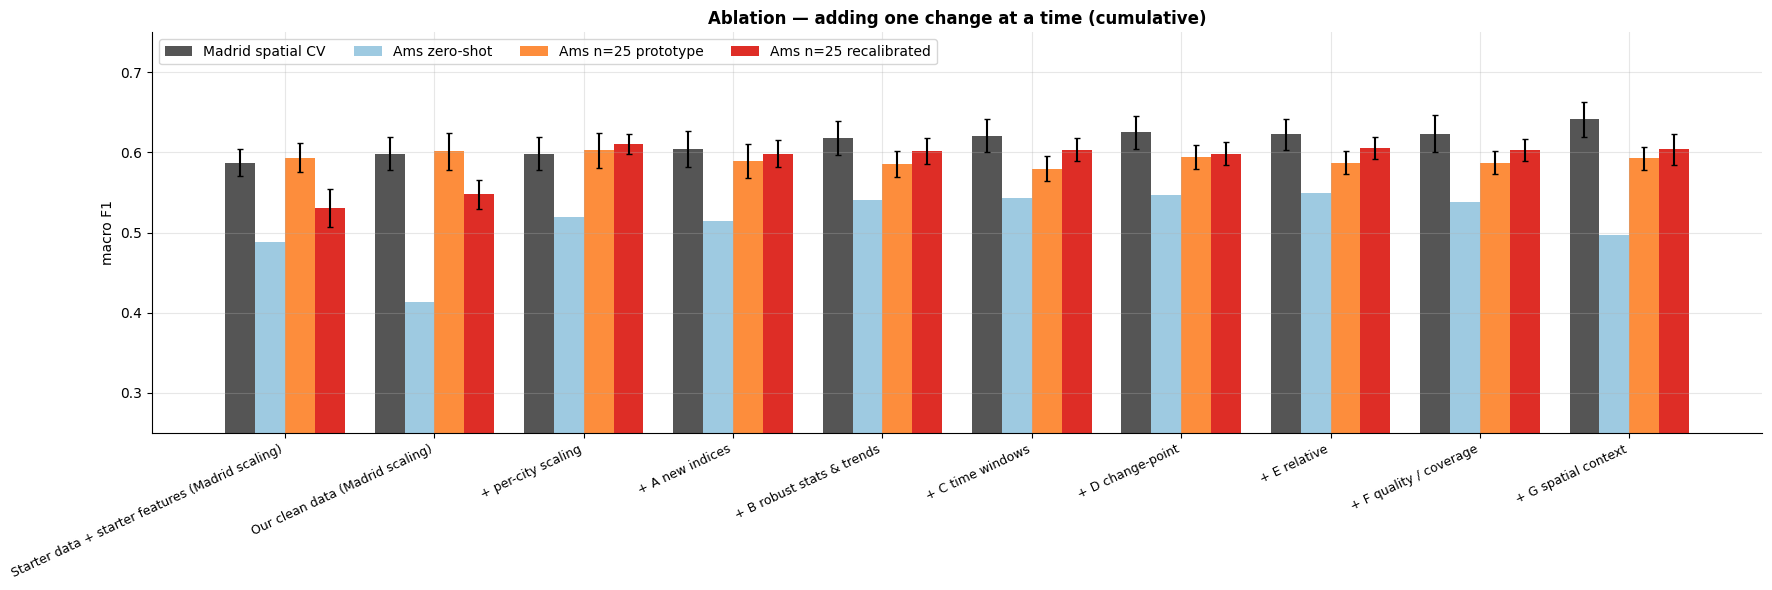

In [19]:
metrics = ['Madrid spatial CV', 'Ams zero-shot', 'Ams n=25 prototype', 'Ams n=25 recalibrated']
errs    = ['Madrid CV ±', None, 'proto ±', 'recal ±']
mcolors = ['#555555', '#9ecae1', '#fd8d3c', '#de2d26']
fig, ax = plt.subplots(figsize=(18, 6))
xs = np.arange(len(ablation)); w = .2
for i, (m_, e_, col) in enumerate(zip(metrics, errs, mcolors)):
    ax.bar(xs + (i - 1.5) * w, ablation[m_], w, yerr=None if e_ is None else ablation[e_], capsize=2, color=col, label=m_)
ax.set_xticks(xs); ax.set_xticklabels([s.split(' ', 1)[1] for s in ablation.experiment], rotation=25, ha='right', fontsize=9)
ax.set_ylabel('macro F1'); ax.set_ylim(.25, max(.75, ablation[metrics].max().max() + .05))
ax.set_title('Ablation — adding one change at a time (cumulative)', fontweight='bold'); ax.legend(ncol=4, loc='upper left')
plt.tight_layout(); plt.show()

### Reading the ablation table

| Step | Madrid spatial CV | Ams zero-shot | Ams n=25 prototype | Ams n=25 recalibrated |
|---|---|---|---|---|
| 0 Starter pipeline | 0.587 | 0.489 | 0.593 ± 0.018 | 0.531 ± 0.024 |
| 1 Our clean data | 0.599 | 0.413 | 0.601 ± 0.023 | 0.548 ± 0.018 |
| 2 + per-city scaling | 0.599 | **0.520** | 0.603 ± 0.022 | **0.611 ± 0.012** |
| 3 + A indices | 0.605 | 0.514 | 0.590 | 0.598 |
| 4 + B robust & trends | 0.618 | 0.540 | 0.586 | 0.602 |
| 5 + C windows | 0.621 | 0.543 | 0.580 | 0.604 |
| 6 + D change-point | 0.625 | 0.546 | 0.594 | 0.598 |
| 7 + E relative | 0.623 | **0.549** | 0.587 | 0.606 |
| 8 + F quality | 0.623 | 0.538 | 0.587 | 0.603 |
| 9 + G spatial | **0.641** | 0.497 | 0.593 | 0.604 |

**What we learned:**
1. **Madrid keeps improving** with every group: 0.587 → **0.641** (+0.054). Clean data, robust trends, change-point and especially **spatial context** (+0.018) all help at home.
2. **Per-city scaling is the single biggest transfer gain**: zero-shot 0.413 → 0.520 and recalibrated n=25 0.548 → 0.611 — with zero Amsterdam labels.
3. **Amsterdam n=25 is flat at ≈ 0.60** whatever features we add (differences ≈ ±0.01 are inside the error bars). **The bottleneck for the low-data prize is the transfer *method*, not the features.**
4. **Spatial features hurt zero-shot** (0.549 → 0.497): neighbourhood structure (density, district patterns) differs between cities, so the Madrid model over-trusts it in Amsterdam.
5. Our clean data alone *lowered* zero-shot with Madrid scaling (0.489 → 0.413) — cleaner features make the city brightness gap sharper — but per-city scaling more than fixes that.

---
# Part 7 — Leave-one-group-out

The ablation adds groups in one fixed order, so a group added late may look useless only because an earlier group already captured the same signal. Here we start from the **full set** and **remove one group at a time**: a large drop means the group carries **unique** information.

(Madrid CV is skipped here to save time — we look at the Amsterdam metrics, which are what the prizes measure.)

In [20]:
FULL = 'SABCDEFG'
logo = []
for g in FULL:
    gs = FULL.replace(g, '')
    r, *_ = evaluate(f'full − {g}', X_of('Madrid', gs), X_of('Amsterdam', gs), cv=False)
    logo.append(r)
logo = pd.DataFrame(logo)
full_row = ablation.iloc[-1]
for m_ in metrics[1:]:
    logo[f'Δ {m_}'] = logo[m_] - full_row[m_]
logo[['experiment', 'n_features'] + [f'Δ {m_}' for m_ in metrics[1:]]].round(3)

full − S                                      feats= 241 | MadCV nan | zero-shot 0.485 | proto 0.574±0.014 | recal 0.586±0.024  (76s)


full − A                                      feats= 279 | MadCV nan | zero-shot 0.493 | proto 0.598±0.014 | recal 0.599±0.018  (93s)


full − B                                      feats= 211 | MadCV nan | zero-shot 0.503 | proto 0.601±0.015 | recal 0.609±0.021  (70s)


full − C                                      feats= 264 | MadCV nan | zero-shot 0.497 | proto 0.599±0.015 | recal 0.599±0.013  (83s)


full − D                                      feats= 263 | MadCV nan | zero-shot 0.493 | proto 0.580±0.015 | recal 0.594±0.019  (82s)


full − E                                      feats= 276 | MadCV nan | zero-shot 0.505 | proto 0.600±0.015 | recal 0.599±0.028  (87s)


full − F                                      feats= 294 | MadCV nan | zero-shot 0.505 | proto 0.592±0.015 | recal 0.602±0.015  (91s)


full − G                                      feats= 265 | MadCV nan | zero-shot 0.538 | proto 0.587±0.014 | recal 0.603±0.014  (79s)


,experiment,n_features,Δ Ams zero-shot,Δ Ams n=25 prototype,Δ Ams n=25 recalibrated
0,full − S,241,-0.012,-0.019,-0.017
1,full − A,279,-0.004,0.005,-0.005
2,full − B,211,0.006,0.008,0.005
3,full − C,264,0.000,0.006,-0.005
4,full − D,263,-0.004,-0.013,-0.010
5,full − E,276,0.008,0.007,-0.005
6,full − F,294,0.008,-0.000,-0.002
7,full − G,265,0.041,-0.005,-0.001


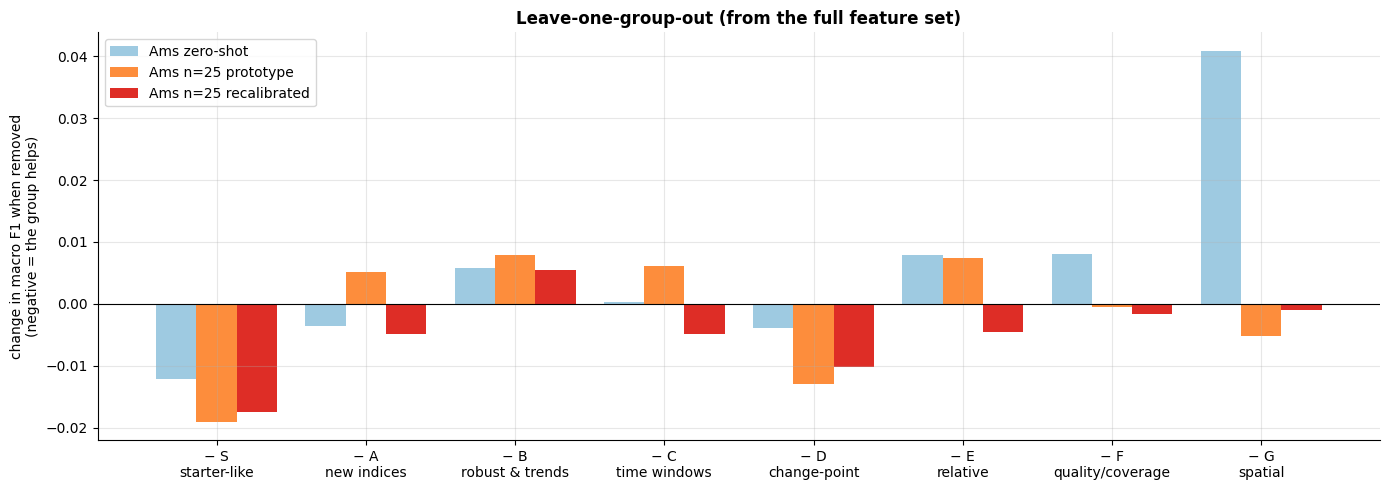

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))
xs = np.arange(len(logo)); w = .27
for i, (m_, col) in enumerate(zip(metrics[1:], mcolors[1:])):
    ax.bar(xs + (i - 1) * w, logo[f'Δ {m_}'], w, color=col, label=m_)
ax.axhline(0, color='k', lw=.8)
names = {'S': 'starter-like', 'A': 'new indices', 'B': 'robust & trends', 'C': 'time windows', 'D': 'change-point',
         'E': 'relative', 'F': 'quality/coverage', 'G': 'spatial'}
ax.set_xticks(xs); ax.set_xticklabels([f'− {g}\n{names[g]}' for g in FULL])
ax.set_ylabel('change in macro F1 when removed\n(negative = the group helps)')
ax.set_title('Leave-one-group-out (from the full feature set)', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.show()

**Reading leave-one-group-out (negative = the group helps):**
- **S (starter-like)** and **D (change-point)** carry **unique** transfer information: removing them costs 0.010–0.019 in the n=25 scores.
- **G (spatial)** is the clearest *negative* for zero-shot: removing it **gains +0.041**.
- B, C, E, F are mostly redundant for transfer (|Δ| ≤ 0.008, within noise) — they help Madrid but not Amsterdam.

➡️ **Decision:** use **two feature sets** — a **rich set (all groups)** for the Madrid model, and a **transfer set (S + D, plus robust indices)** for city-to-city transfer; spatial information is better used *after* prediction (smoothing probabilities within Amsterdam) than as model input.

---
# Part 8 — Label-side experiments

Two ideas from notebook 00, tested on the full feature set:
1. **Coverage weights** — a pixel that is mostly building has a cleaner signal and label, so it counts more in training (`sample_weight = coverage`).
2. **Drop the 1960 pile** — 2 227 Madrid pixels sit exactly on 1960, the class 1/2 boundary, possibly a "default" date. We remove them from **training only** (they stay in every test fold, so scores remain comparable).

In [22]:
Xm_full, Xa_full = X_of('Madrid', FULL), X_of('Amsterdam', FULL)
heap = pixels['Madrid'].wmy.to_numpy() == 1960
label_res = [ablation.iloc[-1].to_dict() | {'experiment': 'full set (reference)'}]
r, *_ = evaluate('full + coverage weights', Xm_full, Xa_full, weight=pixels['Madrid'].coverage.to_numpy()); label_res.append(r)
r, *_ = evaluate('full − 1960 pile in training', Xm_full, Xa_full, train_keep=~heap); label_res.append(r)
pd.DataFrame(label_res)[['experiment'] + metrics].round(3)

full + coverage weights                       feats= 299 | MadCV 0.642 | zero-shot 0.504 | proto 0.593±0.015 | recal 0.609±0.021  (504s)


full − 1960 pile in training                  feats= 299 | MadCV 0.645 | zero-shot 0.491 | proto 0.593±0.015 | recal 0.605±0.020  (464s)


,experiment,Madrid spatial CV,Ams zero-shot,Ams n=25 prototype,Ams n=25 recalibrated
0,full set (reference),0.641,0.497,0.593,0.604
1,full + coverage weights,0.642,0.504,0.593,0.609
2,full − 1960 pile in training,0.645,0.491,0.593,0.605


**Result:**
- **Coverage weights**: small gains everywhere (Madrid 0.642, zero-shot 0.504, recal 0.609) → **keep**.
- **Dropping the 1960 pile**: best Madrid CV (0.645) but lower zero-shot (0.491) → the pile hurts Madrid's 1/2 boundary only; **optional**, not used for transfer.

---
# Part 9 — Few-shot curve for the final feature set

The challenge asks for Amsterdam macro F1 at **n = 5, 25, 50, 100, 200** labelled pixels per class, with error bars, plotted against **log₂ n**. Here is that curve for the full feature set with both transfer methods (10 random draws each). *This is a feature-quality check; the modelling notebook will improve the transfer method itself.*

,prototype mean,recalibrated mean,prototype ±,recalibrated ±
n per class,,,,
5,0.498,0.524,0.047,0.062
25,0.593,0.604,0.015,0.020
50,0.603,0.619,0.013,0.010
100,0.605,0.627,0.004,0.005
200,0.608,0.631,0.010,0.002


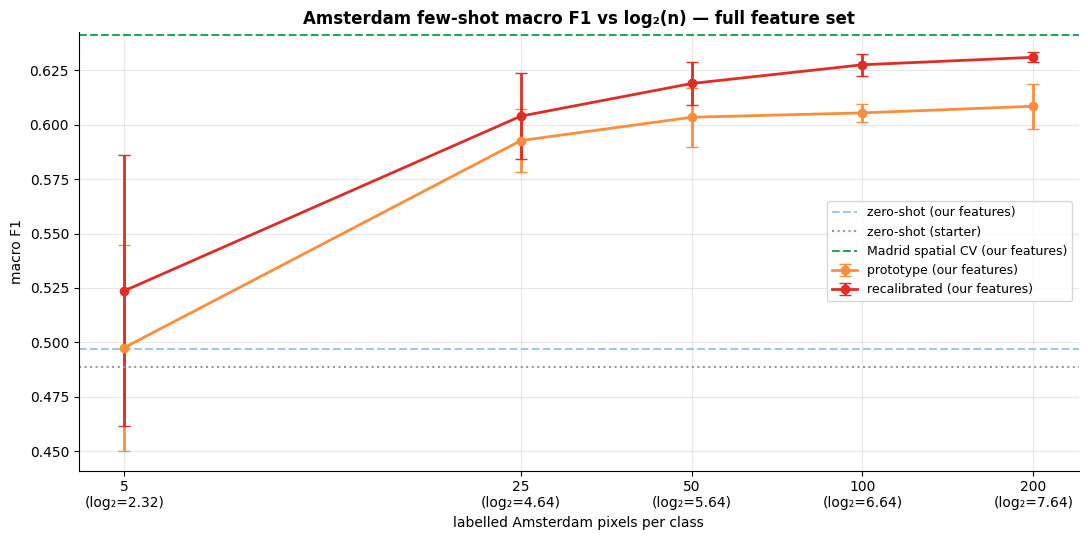

In [23]:
m_full, proba_full, Xa_s_full = models[FULL]
ns = [5, 25, 50, 100, 200]
curve = {'prototype': [], 'recalibrated': []}
for n in ns:
    pr, rc = few_shot(Xa_s_full, proba_full, n)
    curve['prototype'].append((pr.mean(), pr.std())); curve['recalibrated'].append((rc.mean(), rc.std()))
curve_df = pd.DataFrame({f'{k} mean': [v[0] for v in vals] for k, vals in curve.items()} |
                        {f'{k} ±': [v[1] for v in vals] for k, vals in curve.items()}, index=pd.Index(ns, name='n per class'))
display(curve_df.round(3))

base = ablation.iloc[0]
fig, ax = plt.subplots(figsize=(11, 5.5))
for k, col in [('prototype', '#fd8d3c'), ('recalibrated', '#de2d26')]:
    mu = np.array([v[0] for v in curve[k]]); sd = np.array([v[1] for v in curve[k]])
    ax.errorbar(np.log2(ns), mu, yerr=sd, fmt='o-', capsize=4, lw=2, color=col, label=f'{k} (our features)')
ax.axhline(ablation.iloc[-1]['Ams zero-shot'], color='#9ecae1', ls='--', label='zero-shot (our features)')
ax.axhline(base['Ams zero-shot'], color='#999999', ls=':', label='zero-shot (starter)')
ax.axhline(ablation.iloc[-1]['Madrid spatial CV'], color='#2ca25f', ls='--', label='Madrid spatial CV (our features)')
ax.set_xticks(np.log2(ns)); ax.set_xticklabels([f'{n}\n(log₂={np.log2(n):.2f})' for n in ns])
ax.set_xlabel('labelled Amsterdam pixels per class'); ax.set_ylabel('macro F1')
ax.set_title('Amsterdam few-shot macro F1 vs log₂(n) — full feature set', fontweight='bold'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
# Part 10 — Save the features

`features/` gets:
- `madrid_features.parquet`, `amsterdam_features.parquet` — `px_key`, `py_key`, `age_class`, `coverage`, `wmy` + **all feature columns** (unscaled; scale in the modelling notebook, per city).
- `feature_groups.json` — which columns belong to which group (switch groups on/off by name).
- `ablation.csv`, `leave_one_group_out.csv`, `few_shot_curve.csv` — the experiment results for the presentation.

⚠️ `age_class` and `wmy` are saved **next to** the features for convenience — never feed them to a model.

In [24]:
for c in CITIES:
    out = pd.concat([pixels[c][PID + ['age_class', 'wmy']].rename(columns={'wmy': 'wmy_label'}), FEATS[c]], axis=1)
    out.to_parquet(FEAT_DIR / f'{c.lower()}_features.parquet', index=False)
json.dump(GROUP_COLS, open(FEAT_DIR / 'feature_groups.json', 'w'), indent=1)
ablation.to_csv(FEAT_DIR / 'ablation.csv', index=False)
logo.to_csv(FEAT_DIR / 'leave_one_group_out.csv', index=False)
curve_df.to_csv(FEAT_DIR / 'few_shot_curve.csv')
for f in sorted(FEAT_DIR.iterdir()):
    print(f"{f.name:32s} {f.stat().st_size/1e6:7.1f} MB")

ablation.csv                         0.0 MB
amsterdam_features.parquet          46.6 MB
feature_groups.json                  0.0 MB
few_shot_curve.csv                   0.0 MB
leave_one_group_out.csv              0.0 MB
madrid_features.parquet            141.9 MB


---
# Part 11 — Summary & decisions

### Findings
| # | Finding | Evidence |
|---|---|---|
| 1 | Our cleaning + features raise **Madrid** macro F1 from **0.587 → 0.641** (spatial CV) | ablation steps 0 → 9 |
| 2 | **Per-city scaling** is the biggest label-free transfer gain | zero-shot 0.413 → 0.520; n=25 recal 0.548 → 0.611 |
| 3 | **Change-point features** separate built-before vs built-during-the-record classes and carry unique transfer signal | break-strength plots; LOGO −0.013 |
| 4 | **Spatial features** help Madrid (+0.018) but **hurt zero-shot** (−0.041) | ablation step 9; LOGO |
| 5 | Amsterdam n=25 is stuck ≈ 0.60 across feature sets → **improve the transfer method next** | ablation; few-shot curve |
| 6 | Recalibrating the Madrid model beats prototypes from n ≥ 25 (0.631 vs 0.608 at n=200) | Part 9 |
| 7 | Coverage weights: small consistent gain | Part 8 |

### Decisions for the modelling notebook
1. Per-city scaling everywhere.
2. Two feature sets: **rich** (all groups, Madrid) and **transfer** (S + D + selected robust indices).
3. Spatial information → **post-prediction smoothing** within each city rather than model input for transfer.
4. Coverage as sample weight.
5. Focus effort on **transfer methods** (recalibration, fine-tuning with weighted Amsterdam samples, self-training, label spreading, prior-shift correction, ensembles).